In [1]:
import torch
from GAN.src.model import build_res_unet, MainModel
from GAN.src.colorize import lab_to_rgb, colorize_image, visualize_single
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from glob import glob

/Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'dlopen(/Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/torchvision/image.so, 0x0006): Symbol not found: __ZN3c106detail19maybe_wrap_dim_slowIxEET_S2_S2_b
  Referenced from: <9B280146-BBD7-3F77-9873-F9740F2A5329> /Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/torchvision/image.so
  Expected in:     <408F81C0-C6C8-33EF-B02E-B683F7178A71> /Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/torch/lib/libc10.dylib'If you don't plan on using image functional

# CNN

# conditional GAN

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Visualize finetuning loss

In [3]:
# load losses exported from google colab
loss_G = np.load("results/loss_G.npy")
loss_G_L1 = np.load("results/loss_G_L1.npy")
loss_G_GAN = np.load("results/loss_G_GAN.npy")

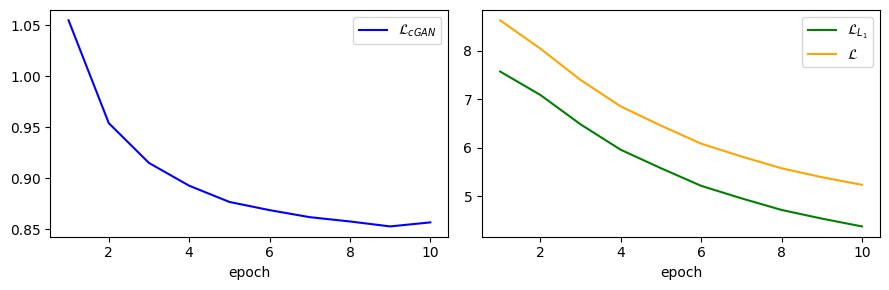

In [4]:
epoch_starts = np.arange(1,3750,375)
n_iter = loss_G.size
epoch_range = np.arange(1,epoch_starts.size+1)
fig, (ax1, ax2) = plt.subplots(1,2, figsize = (9,3))
ax1.plot(epoch_range, loss_G_GAN[epoch_starts], label = r"$\mathcal{L}_{cGAN}$", color = "blue")
ax2.plot(epoch_range, loss_G_L1[epoch_starts], label = r"$\mathcal{L}_{L_1}$", color = "green")
ax2.plot(epoch_range, loss_G[epoch_starts], label = r"$\mathcal{L}$", color = "orange")
ax1.set_xlabel("epoch")
ax2.set_xlabel("epoch")
fig.tight_layout()
ax1.legend()
ax2.legend()
fig.savefig("results/finetuning_loss.jpg", dpi = 400)

### Colorize validation set images

In [5]:
net_G1 = build_res_unet(n_input=1, n_output=2, size=256)
net_G1.load_state_dict(torch.load("GAN/src/checkpoints/res18-unet.pt", map_location=device))

net_G2 = build_res_unet(n_input=1, n_output=2, size=256)
net_G2.load_state_dict(torch.load("GAN/src/checkpoints/res18-unet.pt", map_location=device))

<All keys matched successfully>

In [6]:
# the base model
model1 = MainModel(net_G = net_G1)
model1.load_state_dict(torch.load("GAN/src/checkpoints/final_model_weights.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

In [7]:
# the finetuned model
model2 = MainModel(net_G = net_G2)
model2.load_state_dict(torch.load("GAN/src/checkpoints/model_weights5.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

In [16]:
np.random.seed(44)

In [17]:
val_paths = glob("GAN/data/faces_val/*.jpg")
val_images = np.random.choice(val_paths, 4, replace = False) # choose 4 random images

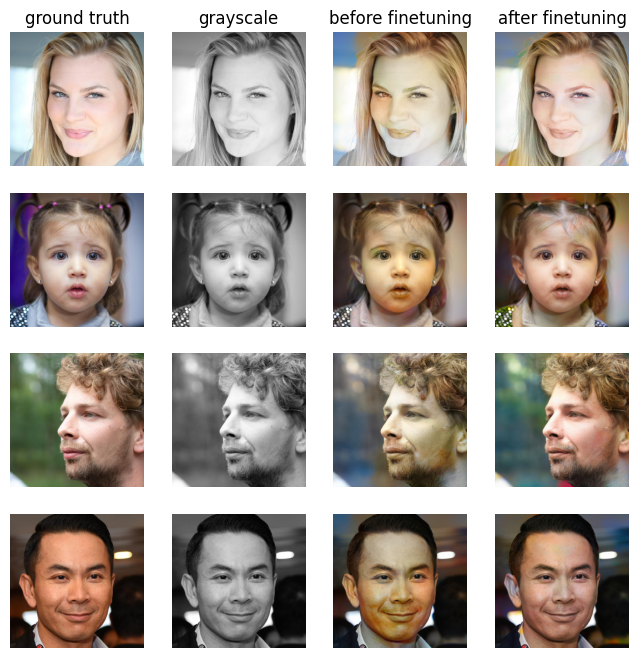

In [18]:
fig, axs = plt.subplots(4,4, figsize=(8,8))
axs[0,0].set_title("ground truth")
axs[0,1].set_title("grayscale")
axs[0,2].set_title("before finetuning")
axs[0,3].set_title("after finetuning")
for i in range(4):
    for j in range(4):
        axs[i,j].axis("off")
    img = Image.open(val_images[i])
    axs[i,0].imshow(img)
    grayscale1, colorized1 = colorize_image(model1, img, return_L=True)
    colorized2 = colorize_image(model2, img, return_L=False)
    axs[i,1].imshow(grayscale1, cmap="gray")
    axs[i,2].imshow(colorized1)
    axs[i,3].imshow(colorized2)
fig.savefig("results/faces_results_gan.jpg")